<a href="https://colab.research.google.com/github/Aditya-Kumar2611/Cognitive-Computing/blob/main/Assignment%208.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question 1**


Original Text:
 
Artificial Intelligence is one of the most fascinating fields of technology.
It allows computers to learn from data and make intelligent decisions.
Machine learning helps systems identify patterns and solve complex problems.
Natural Language Processing enables computers to understand human language.
AI is transforming healthcare, education, transportation, and communication.
I believe artificial intelligence will play an important role in our future.


Cleaned Text:
 
artificial intelligence is one of the most fascinating fields of technology
it allows computers to learn from data and make intelligent decisions
machine learning helps systems identify patterns and solve complex problems
natural language processing enables computers to understand human language
ai is transforming healthcare education transportation and communication
i believe artificial intelligence will play an important role in our future


Words using split():
['artificial', 'intelligence', 'is', 'one

<Axes: title={'center': 'Top 10 Most Frequent Words'}, xlabel='Samples', ylabel='Counts'>

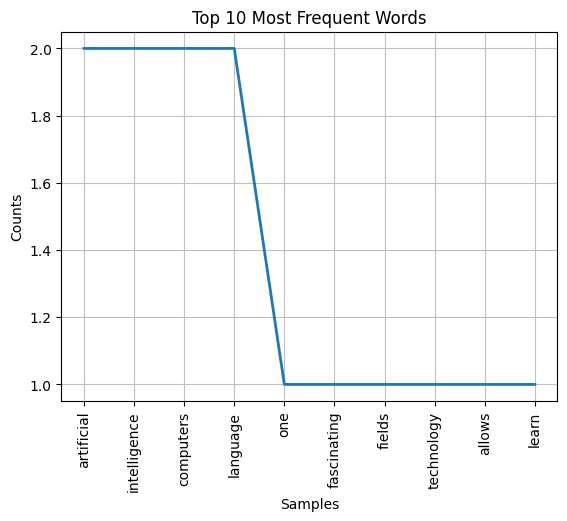

In [4]:

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Download required NLTK datasets
nltk.download('punkt',quiet=True)
nltk.download('punkt_tab',quiet=True)
nltk.download('stopwords',quiet=True)

# 1. Write a unique paragraph (5-6 sentences)
text = """
Artificial Intelligence is one of the most fascinating fields of technology.
It allows computers to learn from data and make intelligent decisions.
Machine learning helps systems identify patterns and solve complex problems.
Natural Language Processing enables computers to understand human language.
AI is transforming healthcare, education, transportation, and communication.
I believe artificial intelligence will play an important role in our future.
"""

print("Original Text:\n", text)

# 2. Convert text to lowercase and remove punctuation using re
cleaned_text = re.sub(r'[^\w\s]', '', text.lower())

print("\nCleaned Text:\n", cleaned_text)

# 3. Tokenize text into words and sentences

# Word tokenization using split()
split_words = cleaned_text.split()

print("\nWords using split():")
print(split_words)

# Word tokenization using NLTK
nltk_words = word_tokenize(cleaned_text)

print("\nWords using word_tokenize():")
print(nltk_words)

# Sentence tokenization
sentences = sent_tokenize(text)

print("\nSentence Tokenization:")
print(sentences)

# Compare split() and word_tokenize()
print("\nComparison:")
print("Number of words using split():", len(split_words))
print("Number of words using word_tokenize():", len(nltk_words))

# 4. Remove stopwords using NLTK
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in nltk_words
    if word not in stop_words
]

print("\nWords after removing stopwords:")
print(filtered_words)

# 5. Display word frequency distribution excluding stopwords
frequency_distribution = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, frequency in frequency_distribution.most_common():
    print(word, ":", frequency)

# Display the frequency distribution graph
frequency_distribution.plot(10, title="Top 10 Most Frequent Words")


**Question 2**

In [5]:

import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required NLTK datasets
nltk.download('stopwords',quiet=True)
nltk.download('wordnet',quiet=True)
nltk.download('omw-1.4',quiet=True)

# Same paragraph used in Q1
text = """
Artificial Intelligence is one of the most fascinating fields of technology.
It allows computers to learn from data and make intelligent decisions.
Machine learning helps systems identify patterns and solve complex problems.
Natural Language Processing enables computers to understand human language.
AI is transforming healthcare, education, transportation, and communication.
I believe artificial intelligence will play an important role in our future.
"""

# 1. Extract all words containing only alphabets using re.findall()
words = re.findall(r'\b[a-zA-Z]+\b', text)

print("Extracted Words:")
print(words)

# 2. Remove stopwords using NLTK
stop_words = set(stopwords.words('english'))

filtered_words = [
    word.lower() for word in words
    if word.lower() not in stop_words
]

print("\nWords after Stopword Removal:")
print(filtered_words)

# 3. Perform stemming using PorterStemmer
porter = PorterStemmer()

stemmed_words = [
    porter.stem(word) for word in filtered_words
]

print("\nStemmed Words:")
print(stemmed_words)

# 4. Perform lemmatization using WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("\nLemmatized Words:")
print(lemmatized_words)

# 5. Compare stemming and lemmatization
print("\nComparison of Stemming and Lemmatization:")

for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(original, "-> Stem:", stem, "| Lemma:", lemma)


Extracted Words:
['Artificial', 'Intelligence', 'is', 'one', 'of', 'the', 'most', 'fascinating', 'fields', 'of', 'technology', 'It', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'and', 'make', 'intelligent', 'decisions', 'Machine', 'learning', 'helps', 'systems', 'identify', 'patterns', 'and', 'solve', 'complex', 'problems', 'Natural', 'Language', 'Processing', 'enables', 'computers', 'to', 'understand', 'human', 'language', 'AI', 'is', 'transforming', 'healthcare', 'education', 'transportation', 'and', 'communication', 'I', 'believe', 'artificial', 'intelligence', 'will', 'play', 'an', 'important', 'role', 'in', 'our', 'future']

Words after Stopword Removal:
['artificial', 'intelligence', 'one', 'fascinating', 'fields', 'technology', 'allows', 'computers', 'learn', 'data', 'make', 'intelligent', 'decisions', 'machine', 'learning', 'helps', 'systems', 'identify', 'patterns', 'solve', 'complex', 'problems', 'natural', 'language', 'processing', 'enables', 'computers', 'understa

Stemming and lemmatization are both important NLP preprocessing techniques used to normalize words and reduce vocabulary size. Stemming uses predefined rules to remove prefixes and suffixes, which can sometimes produce words that do not exist in the dictionary. Lemmatization uses vocabulary and morphological analysis to convert words into their meaningful base forms. Stemming is faster and useful for large-scale text processing, whereas lemmatization is preferred when linguistic accuracy and meaningful word representations are important.

**Question 3**

In [6]:

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Create three short texts (product reviews)
texts = [
    "This laptop has excellent battery life and fast performance.",
    "The smartphone camera is excellent and takes beautiful photos.",
    "This laptop is lightweight and has excellent performance."
]

print("Original Texts:")
for i, text in enumerate(texts, 1):
    print(f"Text {i}: {text}")


# 2. Generate Bag of Words representation using CountVectorizer
count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(texts)

# Get feature names (unique words)
bow_features = count_vectorizer.get_feature_names_out()

print("\nBag of Words Representation:")
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_features,
    index=["Text 1", "Text 2", "Text 3"]
)

print(bow_df)


# 3. Calculate TF-IDF scores using TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

# Get feature names
tfidf_features = tfidf_vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_features,
    index=["Text 1", "Text 2", "Text 3"]
)

print("\nTF-IDF Representation:")
print(tfidf_df.round(3))


# 4. Extract and print top 3 keywords from each text
print("\nTop 3 Keywords from Each Text:")

for i in range(len(texts)):

    # Get TF-IDF scores for the current text
    scores = tfidf_matrix[i].toarray().flatten()

    # Sort word indices by TF-IDF score in descending order
    top_indices = scores.argsort()[::-1][:3]

    print(f"\nText {i+1}:")

    for index in top_indices:
        print(tfidf_features[index], ":", round(scores[index], 3))


Original Texts:
Text 1: This laptop has excellent battery life and fast performance.
Text 2: The smartphone camera is excellent and takes beautiful photos.
Text 3: This laptop is lightweight and has excellent performance.

Bag of Words Representation:
        and  battery  beautiful  camera  excellent  fast  has  is  laptop  \
Text 1    1        1          0       0          1     1    1   0       1   
Text 2    1        0          1       1          1     0    0   1       0   
Text 3    1        0          0       0          1     0    1   1       1   

        life  lightweight  performance  photos  smartphone  takes  the  this  
Text 1     1            0            1       0           0      0    0     1  
Text 2     0            0            0       1           1      1    1     0  
Text 3     0            1            1       0           0      0    0     1  

TF-IDF Representation:
          and  battery  beautiful  camera  excellent   fast    has     is  \
Text 1  0.241    0.408

Interpretation:

Bag of Words counts how often each vocabulary word occurs in each text. TF-IDF assigns higher importance to terms that are useful for distinguishing one document from the others, rather than simply counting occurrences. The top three keywords will be printed automatically. Because these are short texts, some terms may receive similar scores; the actual results depend on the vocabulary and all three documents.

**Question 4**

In [7]:

import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Download required NLTK datasets
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# 1. Write two short texts about different technologies

text1 = """
Artificial Intelligence enables computers to learn from data.
It helps machines make decisions and solve complex problems.
AI is widely used in healthcare, education, and automation.
Machine learning and deep learning are important parts of AI.
"""

text2 = """
Blockchain is a decentralized digital ledger technology.
It stores information securely across multiple computers.
Blockchain is widely used in cryptocurrency and finance.
Smart contracts help automate transactions without intermediaries.
"""

print("Original Texts:")
print("Text 1:", text1)
print("Text 2:", text2)

# 2. Preprocess and tokenize both texts

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)

    tokens = word_tokenize(text)

    stop_words = set(stopwords.words('english'))

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("\nTokens of Text 1:")
print(tokens1)

print("\nTokens of Text 2:")
print(tokens2)

# 3(a). Calculate Jaccard Similarity using sets

set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nJaccard Similarity:")
print("Common Words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

# 3(b). Calculate Cosine Similarity using TF-IDF

documents = [text1, text2]

tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    token_pattern=r'(?u)\b[a-zA-Z]+\b'
)

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

cosine_sim = cosine_similarity(tfidf_matrix[0], tfidf_matrix[1])

print("\nCosine Similarity:")
print(round(cosine_sim[0][0], 4))

# 4. Compare both similarity metrics

print("\nComparison:")
print("Jaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine_sim[0][0], 4))


Original Texts:
Text 1: 
Artificial Intelligence enables computers to learn from data.
It helps machines make decisions and solve complex problems.
AI is widely used in healthcare, education, and automation.
Machine learning and deep learning are important parts of AI.

Text 2: 
Blockchain is a decentralized digital ledger technology.
It stores information securely across multiple computers.
Blockchain is widely used in cryptocurrency and finance.
Smart contracts help automate transactions without intermediaries.


Tokens of Text 1:
['artificial', 'intelligence', 'enables', 'computers', 'learn', 'data', 'helps', 'machines', 'make', 'decisions', 'solve', 'complex', 'problems', 'ai', 'widely', 'used', 'healthcare', 'education', 'automation', 'machine', 'learning', 'deep', 'learning', 'important', 'parts', 'ai']

Tokens of Text 2:
['blockchain', 'decentralized', 'digital', 'ledger', 'technology', 'stores', 'information', 'securely', 'across', 'multiple', 'computers', 'blockchain', 'widely

Analysis:
 Jaccard similarity considers the shared unique words divided by all unique words in both texts. Cosine similarity compares their TF-IDF vectors, accounting for term weighting. Cosine similarity is often more informative when term importance matters. However, neither metric truly understands meaning: AI and Blockchain could be conceptually related even when they use different vocabulary.

**Question 5**

Sentiment Analysis Results:

Review 1: This laptop is amazing. It has excellent performance, a beautiful display and great battery life.
Polarity: 0.812
Subjectivity: 0.912
Sentiment: Positive
------------------------------------------------------------
Review 2: The headphones are terrible. The sound quality is poor and the battery drains very quickly.
Polarity: -0.142
Subjectivity: 0.662
Sentiment: Negative
------------------------------------------------------------
Review 3: The smartphone is okay. It has decent features and average performance.
Polarity: 0.172
Subjectivity: 0.522
Sentiment: Positive
------------------------------------------------------------


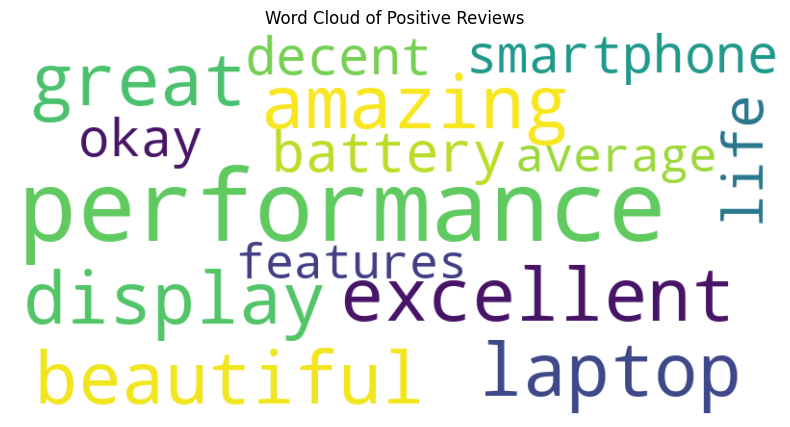

In [8]:

import nltk
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# 1. Write short product reviews
reviews = [
    "This laptop is amazing. It has excellent performance, a beautiful display and great battery life.",
    "The headphones are terrible. The sound quality is poor and the battery drains very quickly.",
    "The smartphone is okay. It has decent features and average performance."
]

# 2. Calculate polarity and subjectivity for each review

positive_reviews = []

print("Sentiment Analysis Results:\n")

for i, review in enumerate(reviews, 1):

    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    # 3. Classify reviews
    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)

    elif polarity < 0:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"

    print(f"Review {i}: {review}")
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
    print("-" * 60)


# 4. Create a word cloud using positive reviews

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(positive_text)

# Display word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()


Interpretation



*   Polarity: Ranges from −1 to +1. Negative values suggest negative sentiment, positive values suggest positive sentiment, and values near zero suggest neutral sentiment.
*   Subjectivity: Ranges from 0 to 1. Higher values indicate more subjective or opinion-based language.

*   Word cloud: Displays frequently occurring words from the reviews classified as positive.







**Question 6**

In [9]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
text = """
Artificial intelligence is changing the world through technology.
Machines can learn from data and perform intelligent tasks.
Machine learning helps computers identify patterns and make predictions.
Deep learning uses neural networks to solve complex problems.
Artificial intelligence is used in healthcare, education and transportation.
It helps doctors analyze medical images and detect diseases.
In education, intelligent systems provide personalized learning experiences.
Robots use artificial intelligence to perform tasks automatically.
Natural language processing helps computers understand human language.
Computer vision allows machines to recognize objects in images.
Artificial intelligence continues to improve through research and innovation.
The future of technology depends on intelligent and responsible development.
"""

# 2. Tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Total unique words:", total_words)

# Convert text into numerical sequences
input_sequences = []

for sentence in text.lower().split('.'):
    sentence = sentence.strip()

    if sentence:
        token_list = tokenizer.texts_to_sequences([sentence])[0]

        for i in range(1, len(token_list)):
            n_gram_sequence = token_list[:i+1]
            input_sequences.append(n_gram_sequence)

# 3. Pad sequences to equal length
max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

# Separate input and output
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

# One-hot encode output labels
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Input shape:", X.shape)
print("Output shape:", y.shape)

# 4. Build a simple LSTM model
model = Sequential([
    Embedding(total_words, 10, input_length=max_sequence_len-1),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# 5. Train the model
model.fit(X, y, epochs=300, verbose=1)

# 6. Generate new text using a seed phrase
def generate_text(seed_text, next_words):

    for _ in range(next_words):

        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len-1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)

        predicted_word_index = np.argmax(predicted, axis=-1)[0]

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text


# Generate 2-3 new lines of text
seed_text = "artificial intelligence"

print("\nGenerated Text:")
print(generate_text(seed_text, 25))


Total unique words: 73
Input shape: (93, 9)
Output shape: (93, 73)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.0430 - loss: 4.2899
Epoch 2/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0753 - loss: 4.2848 
Epoch 3/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0968 - loss: 4.2801
Epoch 4/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0968 - loss: 4.2734
Epoch 5/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0538 - loss: 4.2641
Epoch 6/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0430 - loss: 4.2504    
Epoch 7/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0430 - loss: 4.2293
Epoch 8/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0430 - loss: 4.1991
Epoch 9/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0430 - loss: 4.1353
Epoch 10/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0430 - loss: 4.0844
Epoch 11/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0430 - loss: 4.0849
Epoch 12/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0645

Expected observation : An LSTM model was trained on a custom text dataset to learn word sequences and predict the next word. Using tokenization and sequence generation, the model generated new text from a seed phrase. This demonstrates how deep learning can be used for basic text generation.

The exact generated sentences will vary depending on training and model predictions. Because the training data is small, the generated text may be repetitive or grammatically imperfect.